In [1]:
# 錄製檔切分
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import json
from collections import deque
from collections.abc import Mapping
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.csv as pacsv

# 訓練模型
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import copy
from tqdm import tqdm

## 0. 讀切分檔的函式

In [2]:
# 讀切分檔（原本的 pva_splits.py）
# 切分在 split_breath_modes.ipynb 做：
#   用 trigger 切口，去掉 <0.2 秒和 >10 分鐘的，再看每口的 Mode
#   存成 data\splits\<rec>_split.npz
# build_splits()：npz 轉成 splits\<rec>\ 底下的 breaths.csv / time.npy / wave.npy，轉過的跳過
# load_splits()：合併各錄製檔，預設只留純 PC-AC 的口
#   load_splits(modes=None)        # 全部模式都要
#   load_splits(recs=["1", "3"])   # 只挑某些錄製檔
import glob
import json
import os
from collections.abc import Mapping

import numpy as np
import pandas as pd

ROOT = r"D:\pva_training"
NPZ_DIR = os.path.join(ROOT, "data", "splits")    # split_breath_modes.ipynb 存的 <rec>_split.npz
CACHE_ROOT = os.path.join(ROOT, "data")           # 錄製檔快取 <rec>_cache（load() 建的）
OUT_DIR = os.path.join(ROOT, "splits")         # 轉完每個錄製檔一個資料夾
OUTPUT_MODES = {"PC-AC"}                          # 只留這些模式
WAVE_COLS = ["Pressure (cmH2O)", "Flow (L/min)", "Volume (mL)"]   # wave.npy 的欄位順序
_BIN = {"Time (s)": ("time.bin", np.float64), "Pressure (cmH2O)": ("pressure.bin", np.float64),
        "Flow (L/min)": ("flow.bin", np.float64), "Volume (mL)": ("volume.bin", np.float64)}

def _here(path, name):
    """路徑找不到就改找 notebook 旁邊的同名資料夾"""
    if os.path.isdir(path):
        return path
    alt = os.path.join(os.getcwd(), name)
    return alt if os.path.isdir(alt) else path


def build_splits(npz_dir=NPZ_DIR, cache_root=CACHE_ROOT, out_dir=OUT_DIR, recs=None,
                 overwrite=False, chunk=2_000_000):
    """
    <rec>_split.npz 轉成 out_dir\\<rec>\\ 底下三個檔：
      breaths.csv：每口的資訊，boundary = 這口混到兩種以上模式
      time.npy   ：時間 (總點數,)
      wave.npy   ：波形 (總點數, 3)
    第 i 口 = wave.npy[offset : offset + points]
    """
    npz_dir = _here(npz_dir, os.path.join("data", "splits"))
    cache_root = _here(cache_root, "data")
    paths = sorted(glob.glob(os.path.join(npz_dir, "*_split.npz")))
    if recs is not None:
        recs = {str(r) for r in recs}
        paths = [p for p in paths if os.path.basename(p)[:-len("_split.npz")] in recs]
    if not paths:
        raise FileNotFoundError(f"{npz_dir} 底下沒有 *_split.npz")

    for p in paths:
        rec = os.path.basename(p)[:-len("_split.npz")]
        d = os.path.join(out_dir, rec)
        if os.path.exists(os.path.join(d, "breaths.csv")) and not overwrite:
            print(f"[{rec}] 已轉過，略過（要重轉用 overwrite=True）")
            continue
        with np.load(p) as z:                                      # 只讀每口的資訊，波形不讀
            meta = pd.DataFrame({k[5:]: z[k] for k in z.files if k.startswith("meta_")})
        cache = os.path.join(cache_root, f"{rec}_cache")
        mm = {c: np.memmap(os.path.join(cache, f), dt, mode="r") for c, (f, dt) in _BIN.items()}
        t = mm["Time (s)"]
        s = np.searchsorted(t, meta["start_time"].to_numpy() - 1e-9)
        e = np.searchsorted(t, meta["end_time"].to_numpy() + 1e-9, side="right")
        n = e - s
        if not np.array_equal(n, meta["n_samples"].to_numpy()):
            raise ValueError(f"[{rec}] 快取和切分檔點數對不上，{cache} 可能是別的錄製檔")
        offset = np.concatenate([[0], np.cumsum(n)[:-1]])
        total = int(n.sum())

        os.makedirs(d, exist_ok=True)
        tf = np.lib.format.open_memmap(os.path.join(d, "time.npy.part"), "w+", np.float64, (total,))
        wf = np.lib.format.open_memmap(os.path.join(d, "wave.npy.part"), "w+", np.float32, (total, 3))
        # 分批搬，一批最多 chunk 點
        bounds = np.searchsorted(np.cumsum(n), np.arange(chunk, total + chunk, chunk), side="left") + 1
        a = 0
        for b in np.unique(np.minimum(bounds, len(n))):
            ss, nn, oo = s[a:b], n[a:b], offset[a:b]
            idx = np.repeat(ss - (oo - oo[0]), nn) + np.arange(nn.sum())
            o0 = oo[0]
            tf[o0:o0 + len(idx)] = t[idx]
            for j, c in enumerate(WAVE_COLS):
                wf[o0:o0 + len(idx), j] = mm[c][idx]
            a = b
        tf.flush(); wf.flush()
        del tf, wf
        for f in ("time.npy", "wave.npy"):
            os.replace(os.path.join(d, f + ".part"), os.path.join(d, f))

        out = pd.DataFrame({"breath_id": meta["breath_id"], "mode": meta["modes"],
                            "boundary": meta["n_modes"] > 1,
                            "start_time": meta["start_time"], "end_time": meta["end_time"],
                            "offset": offset, "points": n,
                            "n_modes": meta["n_modes"], "n_polls": meta["n_polls"]})
        out.to_csv(os.path.join(d, "breaths.csv"), index=False)    # 最後才寫，中斷的不會被當成轉好
        with open(os.path.join(d, "source.json"), "w", encoding="utf-8") as f:
            json.dump({"npz": os.path.abspath(p), "cache": os.path.abspath(cache)}, f, ensure_ascii=False)
        pc = (out["mode"] == "PC-AC").sum()
        print(f"[{rec}] {len(out)} 口（純 PC-AC {pc} 口），{total:,} 點 -> {d}")


def load_splits(out_dir=OUT_DIR, recs=None, modes=OUTPUT_MODES, drop_boundary=False):
    """
    合併 out_dir 底下的切分結果，回傳 SplitWaves
      recs          要哪些錄製檔，None = 全部
      modes         只留這些模式，預設 {"PC-AC"}，None = 全部
      drop_boundary 丟掉混到多種模式的口
    key 是 (rec, breath_id)，因為不同錄製檔的 breath_id 會重複
    """
    out_dir = _here(out_dir, os.path.basename(os.path.normpath(out_dir)))
    if recs is None:
        recs = sorted((n for n in os.listdir(out_dir)
                       if os.path.exists(os.path.join(out_dir, n, "breaths.csv"))),
                      key=lambda x: (len(x), x))
    return SplitWaves(out_dir, recs, modes, drop_boundary)


class SplitWaves(Mapping):
    """
    合併後的呼吸波形，當 dict 用：waves[(rec, breath_id)] 是那口的 DataFrame
    waves.breaths 是所有口的清單；波形用 memmap，用到才讀
    """
    def __init__(self, out_dir, recs, modes=None, drop_boundary=False):
        self.out_dir = out_dir
        self._time, self._wave, parts = {}, {}, []
        for r in recs:
            r = str(r)
            d = os.path.join(out_dir, r)
            b = pd.read_csv(os.path.join(d, "breaths.csv"), dtype={"mode": str})
            b.insert(0, "rec", r)
            parts.append(b)
            self._time[r] = np.load(os.path.join(d, "time.npy"), mmap_mode="r")
            self._wave[r] = np.load(os.path.join(d, "wave.npy"), mmap_mode="r")
        b = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(
            columns=["rec", "breath_id", "mode", "boundary", "start_time", "end_time", "offset", "points"])
        if modes is not None:
            b = b[b["mode"].isin(modes)]
        if drop_boundary:
            b = b[~b["boundary"].astype(bool)]
        self.breaths = b.reset_index(drop=True)
        self._keys = list(zip(self.breaths["rec"], self.breaths["breath_id"].astype(int)))
        self._pos = {k: i for i, k in enumerate(self._keys)}

    def __getitem__(self, key):
        row = self.breaths.iloc[self._pos[key]]
        r, a = row["rec"], int(row["offset"])
        b = a + int(row["points"])
        w = np.asarray(self._wave[r][a:b], dtype=np.float64)
        df = pd.DataFrame({"Time (s)": np.array(self._time[r][a:b])})
        for j, c in enumerate(WAVE_COLS):
            df[c] = w[:, j]
        return df

    def __iter__(self):
        return iter(self._keys)

    def __len__(self):
        return len(self._keys)

    def __repr__(self):
        return f"SplitWaves({len(self)} 口, recs={list(self._wave)}, dir={self.out_dir!r})"


def summary(all_waves):
    """印各錄製檔各模式幾口、長度範圍，回傳第一口的 key"""
    b = all_waves.breaths
    print(b.groupby(["rec", "mode"]).size())
    g = b.groupby("rec")["points"].agg(["size", "min", "max"])
    g.columns = ["口數", "最短點數", "最長點數"]
    print(g)
    print(f"合併後共 {len(all_waves)} 口，長度 {b['points'].min()} ~ {b['points'].max()} 點"
          f"（{b['points'].min() / 100:.2f} ~ {b['points'].max() / 100:.2f} 秒）")
    key = next(iter(all_waves))
    print(key)
    return key

## 1. 把原始錄製檔，依據mode切分

In [3]:
build_splits()                 # npz 轉成 splits\<rec>\，轉過的跳過

all_waves = load_splits(recs=["1", "2", "3", "4", "5"])      # 讀 splits，只留純 PC-AC
key = summary(all_waves)       # 看一下各模式口數
all_waves[key].head()

[1] 已轉過，略過（要重轉用 overwrite=True）
[2] 已轉過，略過（要重轉用 overwrite=True）
[3] 已轉過，略過（要重轉用 overwrite=True）
[4] 已轉過，略過（要重轉用 overwrite=True）
rec  mode 
1    PC-AC    131138
2    PC-AC    458853
3    PC-AC      3097
4    PC-AC    306366
5    PC-AC    545157
dtype: int64
         口數  最短點數   最長點數
rec                     
1    131138    71   7722
2    458853    67   4436
3      3097   163   2534
4    306366    60   7006
5    545157    77  13417
合併後共 1444611 口，長度 60 ~ 13417 點（0.60 ~ 134.17 秒）
('1', 2)


,Time (s),Pressure (cmH2O),Flow (L/min),Volume (mL)
0,7.33,8.5,-6.7,0.0
1,7.34,8.5,-6.6,0.0
2,7.35,8.6,-6.4,0.0
3,7.36,8.6,-6.3,0.0
4,7.37,8.6,-5.9,0.0


## 2. 觀察資料集

In [6]:
df_len = all_waves.breaths[["rec", "breath_id", "points", "start_time"]].rename(columns={"start_time": "start_s"})
df_len["duration"] = df_len["points"] / 100

df_len = df_len.sort_values("duration").reset_index(drop=True)
df_len

,rec,breath_id,points,start_s,duration
0,4,18529,60,84074.05,0.60
1,2,594087,67,2025865.62,0.67
2,1,125953,71,543087.62,0.71
3,2,426729,71,1436824.30,0.71
4,2,197371,72,582751.14,0.72
...,...,...,...,...,...
899449,2,601338,4436,2052922.46,44.36
899450,4,282551,4463,1263790.35,44.63
899451,4,60437,4785,256727.50,47.85
899452,4,86996,7006,368269.58,70.06


### 呼吸特徵統計

=== 全部 1444611 口 ===


,口數,平均,標準差,最小,Q1 (25%),T1 (33.3%),中位數,T2 (66.7%),Q3 (75%),最大
時長 (s),1444611,3.97,1.15,0.60,3.39,3.70,3.99,4.23,4.51,134.17
頻率 (次/分),1444611,16.42,5.49,0.45,13.30,14.18,15.04,16.22,17.70,100.00
峰值壓力,1444611,21.94,4.47,0.20,18.50,19.30,22.60,24.70,25.80,56.90
最低壓力,1444611,6.09,2.15,-47.50,4.80,5.00,7.00,7.80,7.90,10.40
吸氣峰值流量,1444611,46.75,13.91,-48.90,37.50,40.40,47.20,51.50,53.50,180.00
吐氣峰值流量,1444611,-38.75,11.24,-180.00,-44.50,-43.10,-39.70,-33.90,-31.50,55.90
最大容積,1444611,511.81,171.47,0.00,383.40,426.60,514.40,567.00,602.10,3199.60


=== 每個錄製檔：呼吸時長 (s) ===


,口數,平均,標準差,最小,Q1 (25%),T1 (33.3%),中位數,T2 (66.7%),Q3 (75%),最大
rec,,,,,,,,,,
1,131138,3.83,0.87,0.71,3.50,3.68,3.99,4.24,4.29,77.22
2,458853,3.63,0.91,0.67,3.30,3.86,3.98,3.99,3.99,44.36
3,3097,3.94,1.12,1.63,2.99,3.31,4.00,4.95,4.97,25.34
4,306366,4.18,0.89,0.60,3.63,3.80,4.15,4.93,4.96,70.06
5,545157,4.18,1.40,0.77,3.31,3.56,4.23,4.95,5.00,134.17


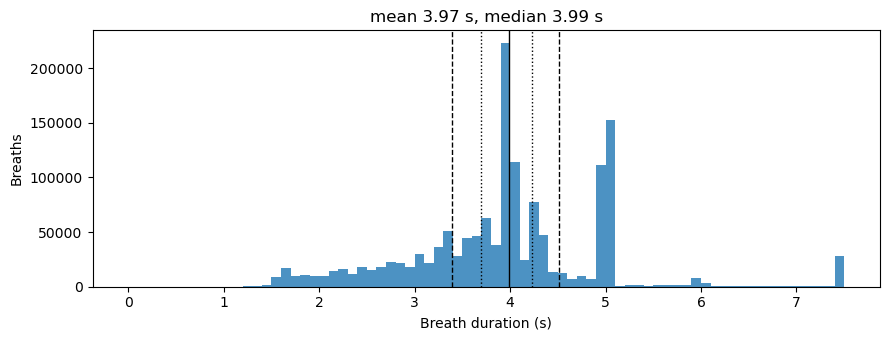

每口特徵存到 breath_features.csv


In [5]:
# 每口算特徵，分批讀 wave.npy
def breath_features(all_waves, chunk=20000):
    b = all_waves.breaths
    out = []
    for rec, grp in b.groupby("rec", sort=False):
        wm = all_waves._wave[rec]                                  # (總點數, 3) memmap
        for s in range(0, len(grp), chunk):
            c = grp.iloc[s:s + chunk]
            o = c["offset"].to_numpy(); n = c["points"].to_numpy()
            lo, hi = int(o.min()), int((o + n).max())
            w = np.vstack([np.asarray(wm[lo:hi], dtype=np.float32), np.zeros((1, 3), np.float32)])
            idx = np.empty(2 * len(c), np.int64)                   # [起點, 終點, 起點, 終點, ...]
            idx[0::2], idx[1::2] = o - lo, o - lo + n               # 偶數位置就是每口的 [起點, 終點)
            mx = np.maximum.reduceat(w, idx, axis=0)[0::2]
            mn = np.minimum.reduceat(w, idx, axis=0)[0::2]
            out.append(pd.DataFrame({
                "rec": rec, "breath_id": c["breath_id"].to_numpy(),
                "duration_s": n / 100,                             # 呼吸時長
                "rr_bpm": 60 / (n / 100),                          # 呼吸頻率（次/分）
                "p_peak": mx[:, 0], "p_min": mn[:, 0],             # 壓力最大 / 最小（cmH2O）
                "f_insp_peak": mx[:, 1], "f_exp_peak": mn[:, 1],   # 吸氣 / 吐氣峰值流量（L/min，吐氣為負）
                "v_max": mx[:, 2],                                 # 容積最大值，約等於潮氣量
            }))
    return pd.concat(out, ignore_index=True)

feat = breath_features(all_waves)

# 平均、標準差、四分位、三分位
PCT = [0.25, 1 / 3, 0.5, 2 / 3, 0.75]
COLS = {"duration_s": "時長 (s)", "rr_bpm": "頻率 (次/分)", "p_peak": "峰值壓力", "p_min": "最低壓力",
        "f_insp_peak": "吸氣峰值流量", "f_exp_peak": "吐氣峰值流量", "v_max": "最大容積"}
def stats(df):
    t = df[list(COLS)].describe(percentiles=PCT).T.rename(index=COLS)
    t = t.rename(columns={"count": "口數", "mean": "平均", "std": "標準差", "min": "最小",
                          "25%": "Q1 (25%)", "33.3%": "T1 (33.3%)", "50%": "中位數",
                          "66.7%": "T2 (66.7%)", "75%": "Q3 (75%)", "max": "最大"})
    t["口數"] = t["口數"].astype(int)
    return t.round(2)

pd.set_option("display.width", 200)
print(f"=== 全部 {len(feat)} 口 ===")
display(stats(feat))

# 每個錄製檔的呼吸時長
print("=== 每個錄製檔：呼吸時長 (s) ===")
by_rec = pd.concat({r: stats(g).loc["時長 (s)"] for r, g in feat.groupby("rec", sort=False)}, axis=1).T
by_rec.index.name = "rec"
by_rec["口數"] = by_rec["口數"].astype(int)
display(by_rec)

# 呼吸時長分佈，虛線四分位、點線三分位
d = feat["duration_s"]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(d, bins=np.arange(0, d.quantile(0.995) + 0.1, 0.1), color="C0", alpha=0.8)
for q, ls in [(0.25, "--"), (0.5, "-"), (0.75, "--"), (1 / 3, ":"), (2 / 3, ":")]:
    ax.axvline(d.quantile(q), color="k", ls=ls, lw=1)
ax.set_xlabel("Breath duration (s)"); ax.set_ylabel("Breaths")
ax.set_title(f"mean {d.mean():.2f} s, median {d.median():.2f} s")
plt.tight_layout(); plt.show()

feat.to_csv("breath_features.csv", index=False)               # 存起來之後直接讀
print("每口特徵存到 breath_features.csv")

## 3. 整理成模型輸入 `(N, 3, 256)`

In [4]:
L = 256                                                  # 重採樣後每口幾點
CH = ["Pressure (cmH2O)", "Flow (L/min)", "Volume (mL)"] # 通道順序跟 wave.npy 一樣

b = all_waves.breaths
keep = (b["points"] >= 20).to_numpy()                    # <0.2 秒的去掉（切分時去過了，應該是 0 口）
dropped = b.loc[~keep, ["rec", "breath_id", "points"]]
kb = b[keep].reset_index(drop=True)                      # 留下的口，順序跟 X 一樣

X = np.empty((len(kb), 3, L), np.float32)
pos = np.linspace(0, 1, L)
CHUNK = 20000                                            # 一批幾口，不然記憶體會爆
for rec, grp in kb.groupby("rec", sort=False):
    wm = all_waves._wave[rec]                            # memmap
    for s in range(0, len(grp), CHUNK):
        c = grp.iloc[s:s + CHUNK]
        n = c["points"].to_numpy()[:, None]
        o = c["offset"].to_numpy()[:, None]
        lo, hi = int(o.min()), int((o + n).max())
        w = np.asarray(wm[lo:hi], dtype=np.float32)      # 只讀這批用到的範圍
        f = o - lo + pos * (n - 1)                       # 每口 L 個點對到 w 的位置（小數）
        i0 = np.floor(f).astype(np.int64)
        i1 = np.minimum(i0 + 1, o - lo + n - 1)
        fr = (f - i0)[..., None].astype(np.float32)
        X[c.index] = (w[i0] * (1 - fr) + w[i1] * fr).transpose(0, 2, 1)   # 線性內插，同 np.interp

ids = list(zip(kb["rec"], kb["breath_id"]))              # 每口的 (錄製檔, breath_id)
lens = kb["points"].to_numpy()

print("X shape =", X.shape)          # (N 口呼吸, 3 通道, 256 點)
print(f"丟掉 {len(dropped)} 口")

X shape = (1444611, 3, 256)
丟掉 0 口


In [5]:
CACHE = rf"D:\pva_training\data\training_data\1to5_PC-AC_L{L}"           # 參數寫在資料夾名稱裡
os.makedirs(CACHE, exist_ok=True)
np.save(os.path.join(CACHE, "X.npy"), X)                       # (N, 3, 256) float32
kb.to_csv(os.path.join(CACHE, "kb.csv"), index=False)          # 每口的資訊，順序跟 X 一樣
dropped.to_csv(os.path.join(CACHE, "dropped.csv"), index=False)
print("已存到", CACHE)

已存到 D:\pva_training\data\training_data\1to5_PC-AC_L256


In [6]:
L = 256
CH = ["Pressure (cmH2O)", "Flow (L/min)", "Volume (mL)"]
CACHE = rf"D:\pva_training\data\training_data\1to5_PC-AC_L{L}"

X = np.load(os.path.join(CACHE, "X.npy"), mmap_mode="r")      # 不加 mmap_mode 就整個讀進記憶體
kb = pd.read_csv(os.path.join(CACHE, "kb.csv"), dtype={"rec": str, "mode": str})
dropped = pd.read_csv(os.path.join(CACHE, "dropped.csv"), dtype={"rec": str})
ids = list(zip(kb["rec"], kb["breath_id"]))
lens = kb["points"].to_numpy()
print("X shape =", X.shape)

X shape = (1444611, 3, 256)
